In [38]:
import sys
sys.path.insert(0, '/home/frlab/mj_opt/mj_sim/manipulator')

import numpy as np
import mujoco
import mujoco.viewer
import pinocchio as pin
from pinocchio import rpy
from core import FixedBaseRobotState, Pinocchio_Wrapper, Mujoco_Kernel
from utils import SimScheduler, Visualizer, DataLogger, plot_helpers
from control import TaskSpaceController, TrajectoryGenerator

%load_ext autoreload
%autoreload 2

# Panda 7-DOF arm + 2-finger gripper
# - Pinocchio: panda_nohand.xml (MJCF, 7-DOF, inertial 풍부)
#   ※ 함께 제공된 panda.urdf는 inertial 0개라 동역학 계산 불가 → MJCF 사용
# - MuJoCo  : scene_torque.xml → panda_torque.xml (9-DOF, motor + 그리퍼 tendon)
# 두 파일 모두 joint 이름이 `joint1`~`joint7` (prefix 없음) → 매핑 단순
MJCF       = '/home/frlab/mj_opt/xmls/systems/panda/scene_torque.xml'
PANDA_XML  = '/home/frlab/mj_opt/xmls/robots/panda/xml/panda_nohand.xml'

# Pinocchio frame 이름 — MJCF body 기준
# grasp: link7 → attachment(+0.107m) → grasp(+0.103m) = 손가락 사이 중심 (TCP, link7로부터 ~0.21m)
PANDA_FRAMES = {
    "ee":   "grasp",
    "base": "link0",
}

# 그리퍼 actuator (panda_torque.xml의 actuator8 = tendon split)
GRIPPER_ACTUATOR_IDX = 7
GRIPPER_OPEN  = 255   # tendon length 0.04 (max open)
GRIPPER_CLOSE = 0

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### State container + Orchestrator
- `PandaState`: NQ=NV=9 (MJCF 전체 매칭). 7 arm + 2 finger view 분리.
- `RobotOrchestrator`: 9-DOF state → Pinocchio에는 `state.q[:7]` 슬라이싱 전달.

In [39]:
class PandaState(FixedBaseRobotState):
    """Panda — 9-DOF (7 arm + 2 finger). MJCF q/dq 크기와 일치."""
    NQ = 9
    NV = 9

    def __init__(self):
        self._q  = np.zeros(self.NQ)
        self._dq = np.zeros(self.NV)
        # arm/finger 분리 view (numpy slice = view)
        self.arm_pos    = self._q[0:7]
        self.arm_vel    = self._dq[0:7]
        self.finger_pos = self._q[7:9]
        self.finger_vel = self._dq[7:9]


class RobotOrchestrator:
    """Panda impedance — q/dq 9차원, Pinocchio에는 [:7] 슬라이싱."""

    def __init__(self, kernel, wrapper, controller, traj, logger=None):
        self.kernel = kernel
        self.wrapper = wrapper
        self.controller = controller
        self.traj = traj
        self.logger = logger

        # 메모리 미리 할당
        self.target_pos = np.zeros(3)
        self.target_R   = np.eye(3)
        self.target_twist = np.zeros(6)

        self.current_ee_pos = np.zeros(3)
        self.current_ee_R   = np.eye(3)
        self.current_twist  = np.zeros(6)

        self.ctrl_tau = np.zeros(wrapper.nv)   # 7 (arm only)


    def on_control(self, t):
        # 1. 상태 업데이트 (MJCF 9-DOF → Pinocchio 7-DOF 슬라이싱)
        self.kernel.update_robot_state(state)
        self.wrapper.update_model(state.q[:7], state.dq[:7])

        # 2. 궤적 평가
        interpolated_oM_ee, target_twist_new = self.traj.evaluate(t)
        self.target_pos[:]   = interpolated_oM_ee.translation
        self.target_R[:]     = interpolated_oM_ee.rotation
        self.target_twist[:] = target_twist_new

        # 3. 현재 EE 상태
        oMf, v_lin, v_ang = self.wrapper.ee_state_world("ee")
        self.current_ee_pos[:]  = oMf.translation
        self.current_ee_R[:]    = oMf.rotation
        self.current_twist[:3]  = v_lin
        self.current_twist[3:]  = v_ang

        # 4. 제어 연산
        pose_err, twist_err = self.controller.compute_error(
            self.current_ee_pos, self.current_ee_R, self.current_twist,
            self.target_pos,     self.target_R,     self.target_twist
        )

        # 5. Impedance 토크 (7-DOF arm only)
        self.ctrl_tau[:] = self.controller.compute_impedance_torque(
            pose_err, twist_err,
            self.wrapper.J_world("ee"),
            self.wrapper.M_inv,
            self.wrapper.nle
        )
        self.kernel.ctrl_tau = self.ctrl_tau

        # 그리퍼는 fixed (open 상태 유지) — 직접 ctrl 인덱스 접근
        self.kernel.data.ctrl[GRIPPER_ACTUATOR_IDX] = GRIPPER_OPEN

        # 6. 로깅
        if self.logger is not None:
            self.logger.log(
                times       = t,
                target_pos  = self.target_pos,
                actual_pos  = self.current_ee_pos,
                target_vel  = self.target_twist[:3],
                actual_vel  = self.current_twist[:3],
                cmd_tau     = self.ctrl_tau,                            # (7,)
                act_tau     = self.kernel.data.qfrc_actuator[:7],       # arm only
                q           = self.kernel.data.qpos[:7],
                dq          = self.kernel.data.qvel[:7],
                ddq         = self.kernel.data.qacc[:7],
            )

    def on_render(self, t, visualizer):
        visualizer.draw_axes(self.current_ee_pos, self.current_ee_R, size=0.15)
        visualizer.draw_axes(self.target_pos,     self.target_R,     size=0.15)

### 시스템 호출
- URDF 7-DOF (panda_joint1~7) → Pinocchio
- MJCF 9-DOF (joint1~7 + finger1~2) → MuJoCo
- joint name 매핑: URDF `panda_joint*` → MJCF `joint*` (prefix strip)

In [40]:
state    = PandaState()
# panda_nohand.xml (MJCF) → Pinocchio: 7-DOF, joint name = joint1~7, frame name = link0~7
wrapper  = Pinocchio_Wrapper(PANDA_XML, frames=PANDA_FRAMES)

# Joint name 매핑 — MJCF 기반이라 prefix strip 불필요
joint_names = [wrapper.model.names[i] for i in range(1, wrapper.model.njoints)]
print(f'Pinocchio joints: {joint_names}')

kernel     = Mujoco_Kernel(MJCF, joint_names_pin_order=joint_names)
controller = TaskSpaceController(wrapper)

print(f"\n✅ 시스템 호출 완료")
print(f"   wrapper.nv = {wrapper.nv}  (Pinocchio 7-DOF)")
print(f"   wrapper.mass = {wrapper.mass:.3f} kg")
print(f"   kernel.model.nq = {kernel.model.nq}, nu = {kernel.model.nu}  (MuJoCo 9-DOF + 1 grip actuator)")
print(f"   _tau_perm = {kernel._tau_perm}")

# 키프레임 자세 (MJCF는 9-DOF, Pinocchio는 7-DOF → 슬라이스)
q_init_full  = kernel.q_keyframe                  # (9,) — 7 arm + 2 finger
dq_init_full = np.zeros(kernel.model.nv)
wrapper.update_model(q_init_full[:7], dq_init_full[:7])

oM_ee_init   = wrapper.oM_ee
init_ee_pos  = oM_ee_init.translation.copy()
init_ee_R    = oM_ee_init.rotation.copy()

print(f"\n초기 자세 (keyframe arm 7-DOF): {q_init_full[:7]}")
print(f"초기 EE 위치 [m]: {init_ee_pos}")
print(f"초기 EE 방향 (R[2]): {init_ee_R[:, 2]}")

Pinocchio joints: ['joint1', 'joint2', 'joint3', 'joint4', 'joint5', 'joint6', 'joint7']

✅ 시스템 호출 완료
   wrapper.nv = 7  (Pinocchio 7-DOF)
   wrapper.mass = 16.062 kg
   kernel.model.nq = 9, nu = 8  (MuJoCo 9-DOF + 1 grip actuator)
   _tau_perm = [0 1 2 3 4 5 6]

초기 자세 (keyframe arm 7-DOF): [ 0.       0.       0.      -1.57079  0.       1.57079 -0.7853 ]
초기 EE 위치 [m]: [ 5.54499478e-01 -1.45105610e-16  5.21502429e-01]
초기 EE 방향 (R[2]): [ 1.18584613e-20 -4.44089210e-16 -1.00000000e+00]


In [41]:
# 목표 위치 — 초기 EE 주변 직사각형 + 회전 시퀀스
wp_pos = [
    init_ee_pos,
    init_ee_pos + np.array([ 0.10,  0.15,  0.00]),
    init_ee_pos + np.array([-0.10,  0.15, -0.10]),
    init_ee_pos + np.array([-0.10, -0.15, -0.10]),
    init_ee_pos + np.array([ 0.10, -0.15,  0.00]),
    init_ee_pos,
]

# 목표 회전 — 시작 자세 유지 (orientation tracking은 보너스)
wp_rot = [init_ee_R] * len(wp_pos)

# 경로 생성 — target_speed = 0.1 m/s
traj = TrajectoryGenerator(
    wp_list=wp_pos,
    R_list=wp_rot,
    target_speed=0.2
)
print(f"Waypoints: {len(wp_pos)}개, target_speed=0.1 m/s")

Waypoints: 6개, target_speed=0.1 m/s


### Main Loop (상태 갱신, 제어, 뷰어)

In [42]:
# 실행 직전 초기화
kernel.reset_to_keyframe()
logger = DataLogger()

# 오케스트레이터 + 스케줄러
orch  = RobotOrchestrator(kernel, wrapper, controller, traj, logger)
sched = SimScheduler(kernel.model, kernel.data, ctrl_hz=500, render_hz=60)
sched.run(on_control=orch.on_control, on_render=orch.on_render)

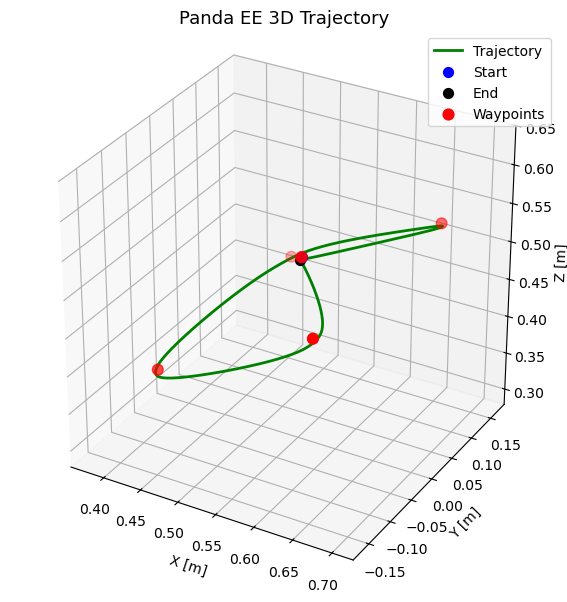

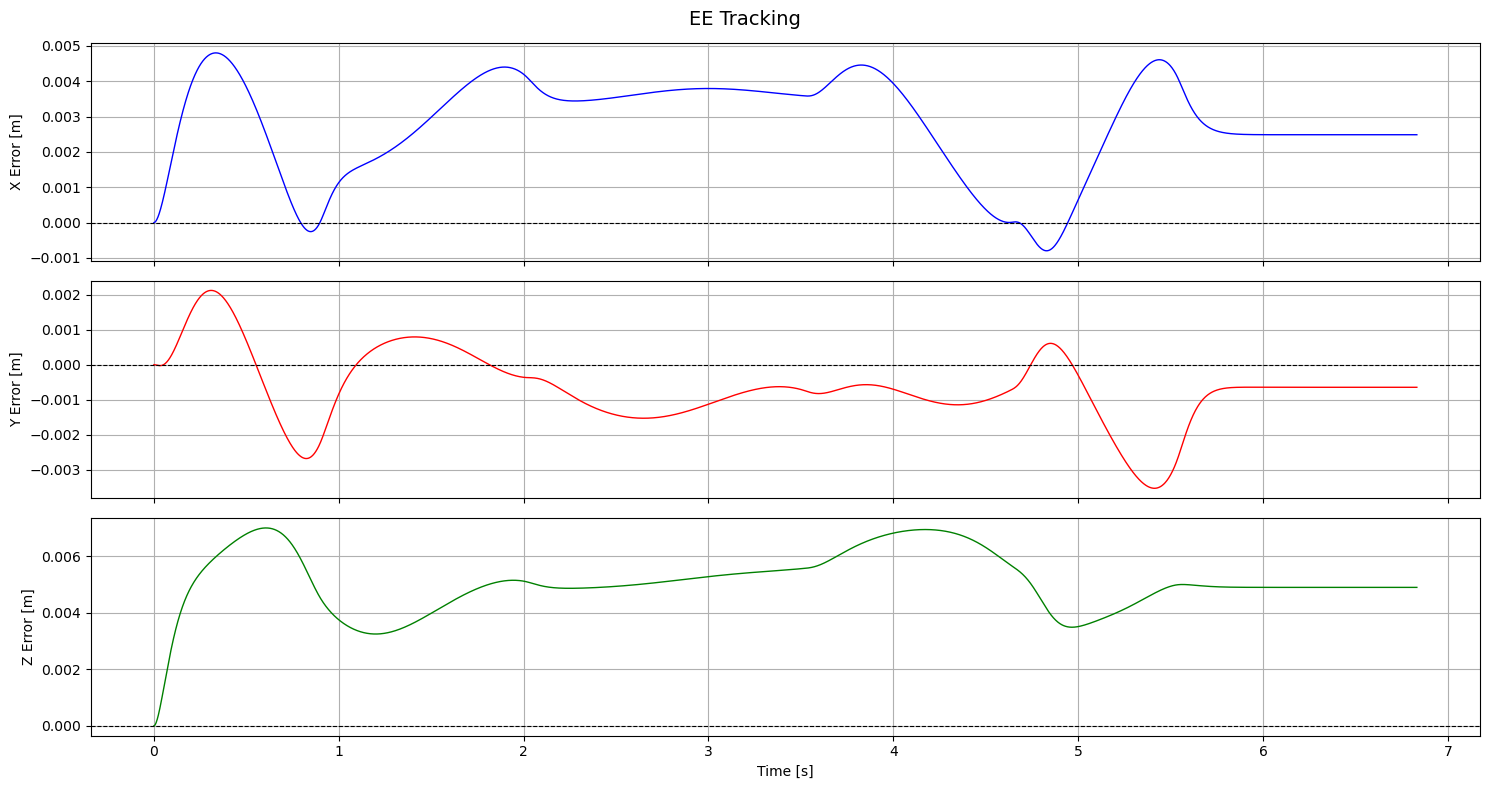

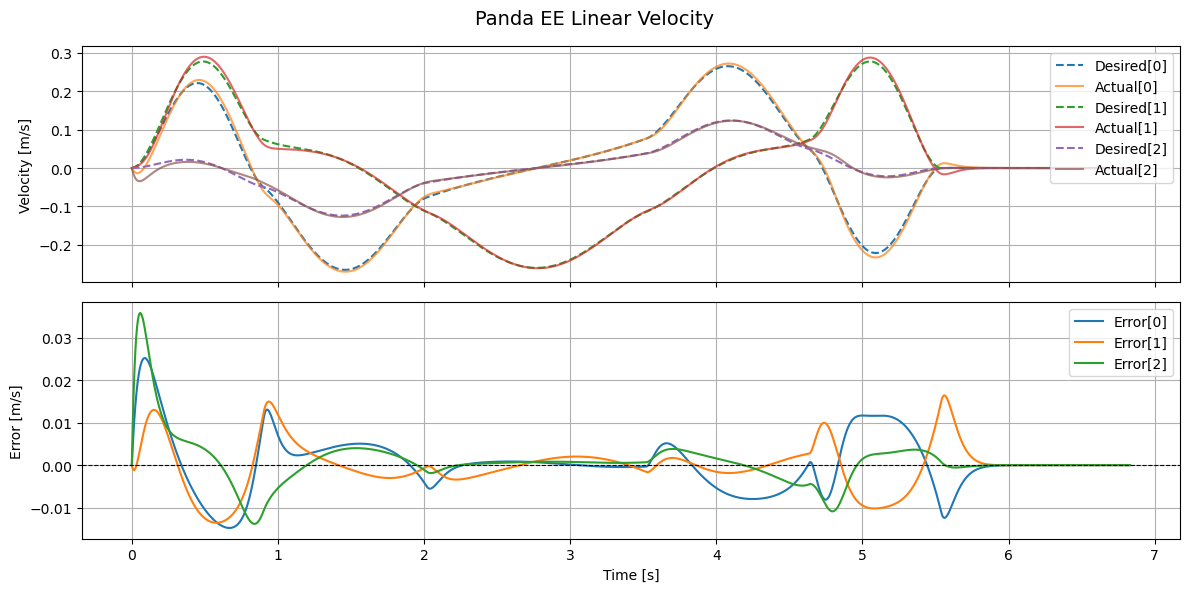

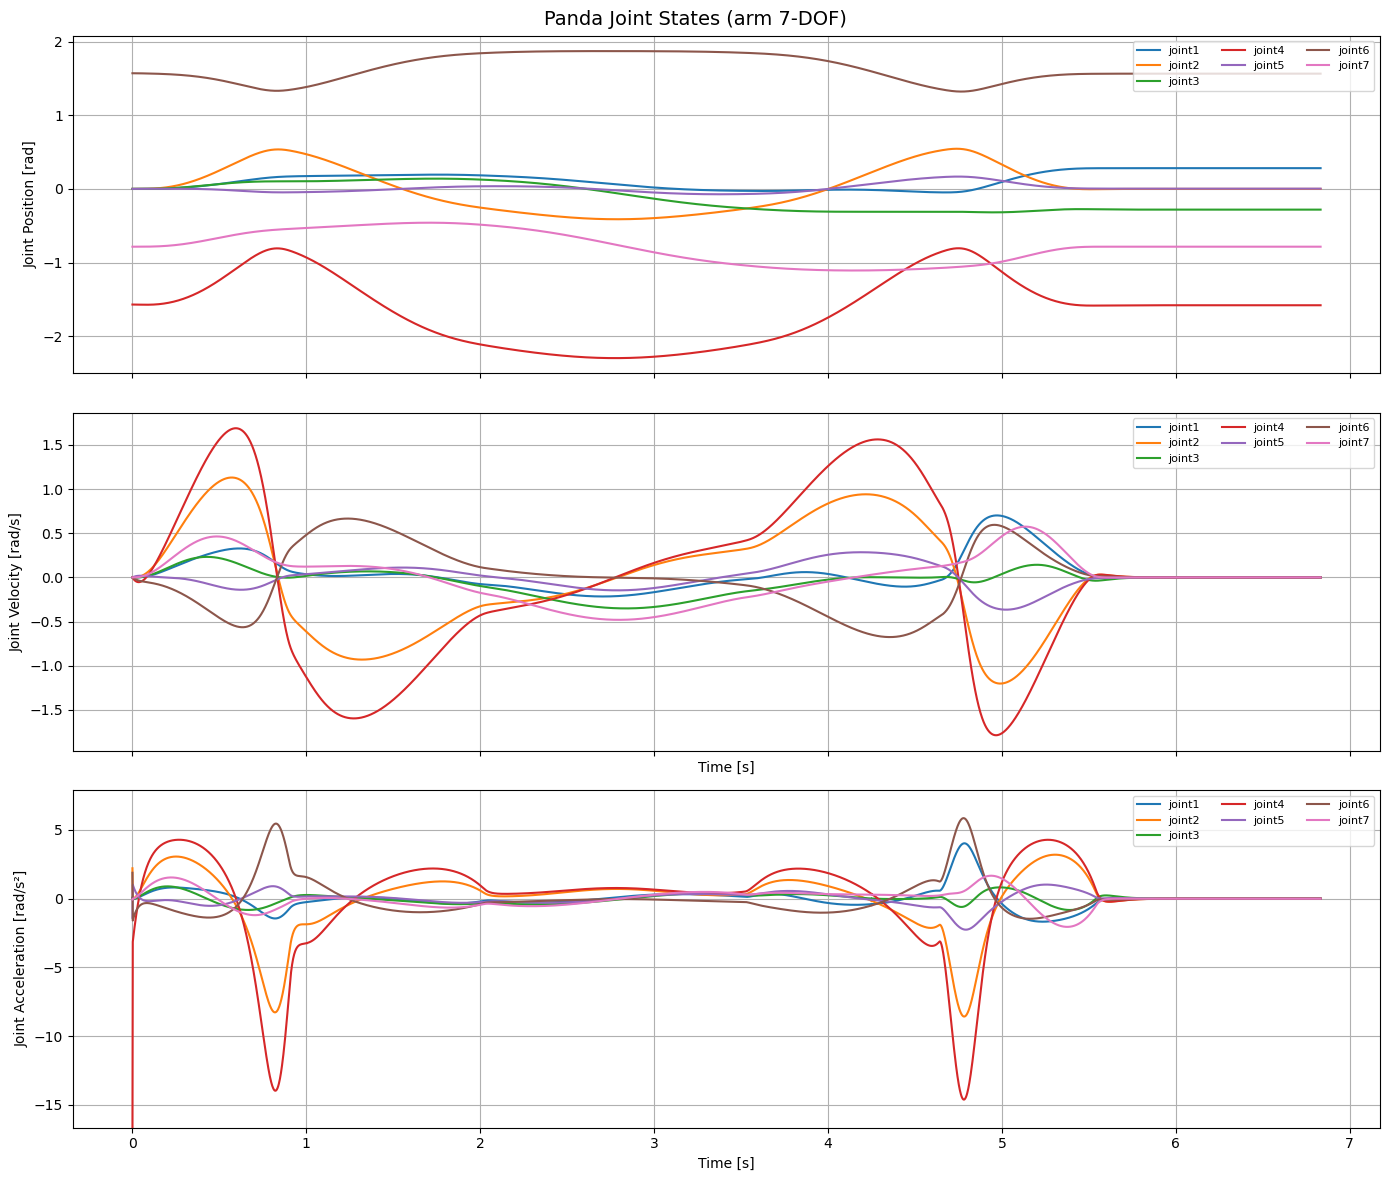

X: max = +0.0048 m @ t=0.334s  |  min = -0.0008 m @ t=4.828s  |  |max| = 0.0048 m  |  RMS = 0.0031 m
Y: max = +0.0021 m @ t=0.310s  |  min = -0.0035 m @ t=5.412s  |  |max| = 0.0035 m  |  RMS = 0.0012 m
Z: max = +0.0070 m @ t=0.606s  |  min = +0.0000 m @ t=0.000s  |  |max| = 0.0070 m  |  RMS = 0.0052 m


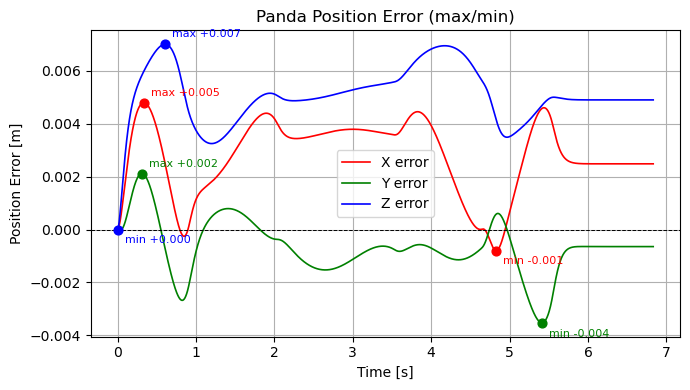

{'X': {'max': 0.004801404227954498,
  'max_t': 0.33400000000000024,
  'min': -0.0007970092499752779,
  'min_t': 4.827999999999947,
  'abs_max': 0.004801404227954498,
  'rms': 0.0030976071014170606},
 'Y': {'max': 0.002119157170480987,
  'max_t': 0.3100000000000002,
  'min': -0.0035286708957088216,
  'min_t': 5.412000000000142,
  'abs_max': 0.0035286708957088216,
  'rms': 0.001230365424259555},
 'Z': {'max': 0.007009953390603729,
  'max_t': 0.6060000000000004,
  'min': 0.0,
  'min_t': 0.0,
  'abs_max': 0.007009953390603729,
  'rms': 0.005188540124601575}}

In [43]:
# 1. 로거 데이터 추출
times      = logger.get('times')
target_pos = logger.get('target_pos')
actual_pos = logger.get('actual_pos')
target_vel = logger.get('target_vel')
actual_vel = logger.get('actual_vel')
q          = logger.get('q')
dq         = logger.get('dq')
ddq        = logger.get('ddq')

# 2. 시각화
plot_helpers.plot_3d_trajectory(
    pos_log=actual_pos,
    waypoints=wp_pos,
    title="Panda EE 3D Trajectory"
)

plot_helpers.plot_ee_tracking(
    times=times,
    desired=target_pos,
    actual=actual_pos
)

plot_helpers.plot_velocity_tracking(
    times=times,
    des_vel=target_vel,
    act_vel=actual_vel,
    title="Panda EE Linear Velocity"
)

plot_helpers.plot_joint_state(
    times=times,
    q=q, dq=dq, ddq=ddq,
    joint_names=joint_names,
    title="Panda Joint States (arm 7-DOF)"
)

# 3. 추종 오차 통계
err = target_pos - actual_pos
plot_helpers.summarize_tracking_error(
    times, err,
    axes=('X', 'Y', 'Z'),
    plot_axes=('X', 'Y', 'Z'),
    title="Panda Position Error (max/min)",
)